# The Paradox of Equality: Redistribution in a Malthusian Economy

ECON 324, Written Assignment 1

This notebook simulates a Malthusian economy in which a small group of elites, the Lords, takes half of everything workers produce. We compare two scenarios:

1. **Lords remain:** the Lords keep taking half of output forever.
2. **Rebellion:** in generation 20, the workers overthrow the Lords and keep everything they produce.

We first solve the model with no randomness. Then we add random harvests and random births and run the comparison 5,000 times (a Monte Carlo simulation). This shows how much uncertainty changes the transition and how long the workers' gains last.

All parameter values are illustrative. They are not estimates for any real society.

## 1. The model

The model follows the lecture's production function and the household model in Ashraf and Galor (2011, Section I).

**Production.** $L$ workers farm a fixed amount of land $H$:

$$Y = A\,L^{\alpha} H^{1-\alpha}$$

Because land is fixed, each extra worker adds less than the one before (diminishing returns). Output per worker $y = Y/L$ therefore falls as population grows.

**The Lords.** They take a share $\tau$ of output. Each worker keeps

$$w = (1-\tau)\,y$$

**Households.** Each worker splits $w$ between their own consumption $c$ and raising children, each of whom costs $\rho$. They care about both, with utility $u = c^{1-\gamma} n^{\gamma}$. The best choice is to spend a fixed share on each:

$$c = (1-\gamma)\,w \qquad n = \frac{\gamma\,w}{\rho}$$

**Population.** Each worker's surviving children are the next generation's workers:

$$L_{\text{next}} = n \times L$$

When workers keep more, they raise more children. More workers then means less land per worker, which pushes income back down. That feedback is the Malthusian mechanism.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE = "#2a78d6", "#eb6834"

APPENDIX = Path("Appendix")
APPENDIX.mkdir(exist_ok=True)

| Parameter | Meaning | Value |
|---|---|---|
| $A$ | technology | 1 |
| $H$ | land | 100,000 |
| $\alpha$ | labor share of output | 0.65 |
| $\gamma$ | how much parents value children | 0.30 |
| $\rho$ | cost of raising a child | 0.30 |
| $\tau$ | share taken by the Lords | 0.5, or 0 after the rebellion |

In [16]:
params = {"A": 1.0, "H": 100000, "alpha": 0.65, "gamma": 0.30, "rho": 0.30}

TAX_LORDS = 0.5
REBELLION = 20
GENERATIONS = 121


def generation(L, tax, p=params, shock=1.0):
    Y = p["A"] * shock * L ** p["alpha"] * p["H"] ** (1 - p["alpha"])
    y = Y / L
    w = (1 - tax) * y
    c = (1 - p["gamma"]) * w
    n = p["gamma"] * w / p["rho"]
    u = c ** (1 - p["gamma"]) * n ** p["gamma"]
    return {"population": L, "output": Y, "output_per_worker": y, "income": w, "consumption": c, "children": n, "utility": u}

## 2. Equilibrium with and without the Lords

Population stops changing when each worker raises exactly one surviving child ($n = 1$). That requires income $w = \rho/\gamma$. Solving for the population that delivers this income gives

$$L^* = H\left[\frac{A(1-\tau)\gamma}{\rho}\right]^{\frac{1}{1-\alpha}}$$

The tax $\tau$ changes the equilibrium *population* but not equilibrium *income*. Workers always end up at $w = \rho/\gamma$. With the Lords present, population settles where each worker produces twice that amount, so that after handing over half they keep exactly $\rho/\gamma$.

In [18]:
def equilibrium_population(tax, p=params):
    return p["H"] * (p["A"] * (1 - tax) * p["gamma"] / p["rho"]) ** (1 / (1 - p["alpha"]))


with_lords = generation(equilibrium_population(TAX_LORDS), TAX_LORDS)
without_lords = generation(equilibrium_population(0), 0)

table = pd.DataFrame({"With Lords": with_lords, "Without Lords": without_lords})
table["Ratio"] = table["Without Lords"] / table["With Lords"]
table

,With Lords,Without Lords,Ratio
population,"13,801.1","100,000",7.24579
output,"27,602.2","100,000",3.62289
output_per_worker,2,1,0.5
income,1,1,1
consumption,0.7,0.7,1
children,1,1,1
utility,0.779056,0.779056,1


Without the Lords, the long-run economy has about 7.2 times as many workers and 3.6 times as much total output, but output per worker is half as large. Income, consumption and utility are exactly the same as under the Lords.

In general, the population ratio is $2^{1/(1-\alpha)}$ and the output ratio is $2^{\alpha/(1-\alpha)}$, while output per worker always halves.

## 3. The rebellion, step by step

We start the economy at its equilibrium with the Lords and simulate 121 generations. In each generation:

1. the current workers produce output,
2. the Lords take their share (if they are still there),
3. workers choose consumption and children,
4. the children become the next generation's workers.

Because the children only grow up in the following generation, the rebellion changes consumption right away but changes population one generation later.

In [19]:
def tax_path(rebellion):
    taxes = np.full(GENERATIONS, TAX_LORDS)
    if rebellion:
        taxes[REBELLION:] = 0
    return taxes

def simulate(taxes, L0, p=params):
    rows = []
    L = L0
    for tax in taxes:
        result = generation(L, tax, p)
        rows.append(result)
        L = result["children"] * L
    return pd.DataFrame(rows)


L0 = equilibrium_population(TAX_LORDS)
rebel = simulate(tax_path(rebellion=True), L0)
lords = simulate(tax_path(rebellion=False), L0)

rebel.loc[18:26].round(3)

,population,output,output_per_worker,income,consumption,children,utility
18,"13,801.1","27,602.2",2,1,0.7,1,0.779
19,"13,801.1","27,602.2",2,1,0.7,1,0.779
20,"13,801.1","27,602.2",2,2,1.4,2,1.558
21,"27,602.2","43,312.6",1.569,1.569,1.098,1.569,1.222
22,"43,312.6","58,049.6",1.34,1.34,0.938,1.34,1.044
23,"58,049.6","70,221.4",1.21,1.21,0.847,1.21,0.942
24,"70,221.4","79,470.3",1.132,1.132,0.792,1.132,0.882
25,"79,470.3","86,125.8",1.084,1.084,0.759,1.084,0.844
26,"86,125.8","90,747.9",1.054,1.054,0.738,1.054,0.821


In generation 20 output does not change, because the same number of people farm the same land. But workers now keep all of it, so income, consumption, children per worker and utility all double. From generation 21 the population grows, output per worker falls, and consumption slides back toward where it started.

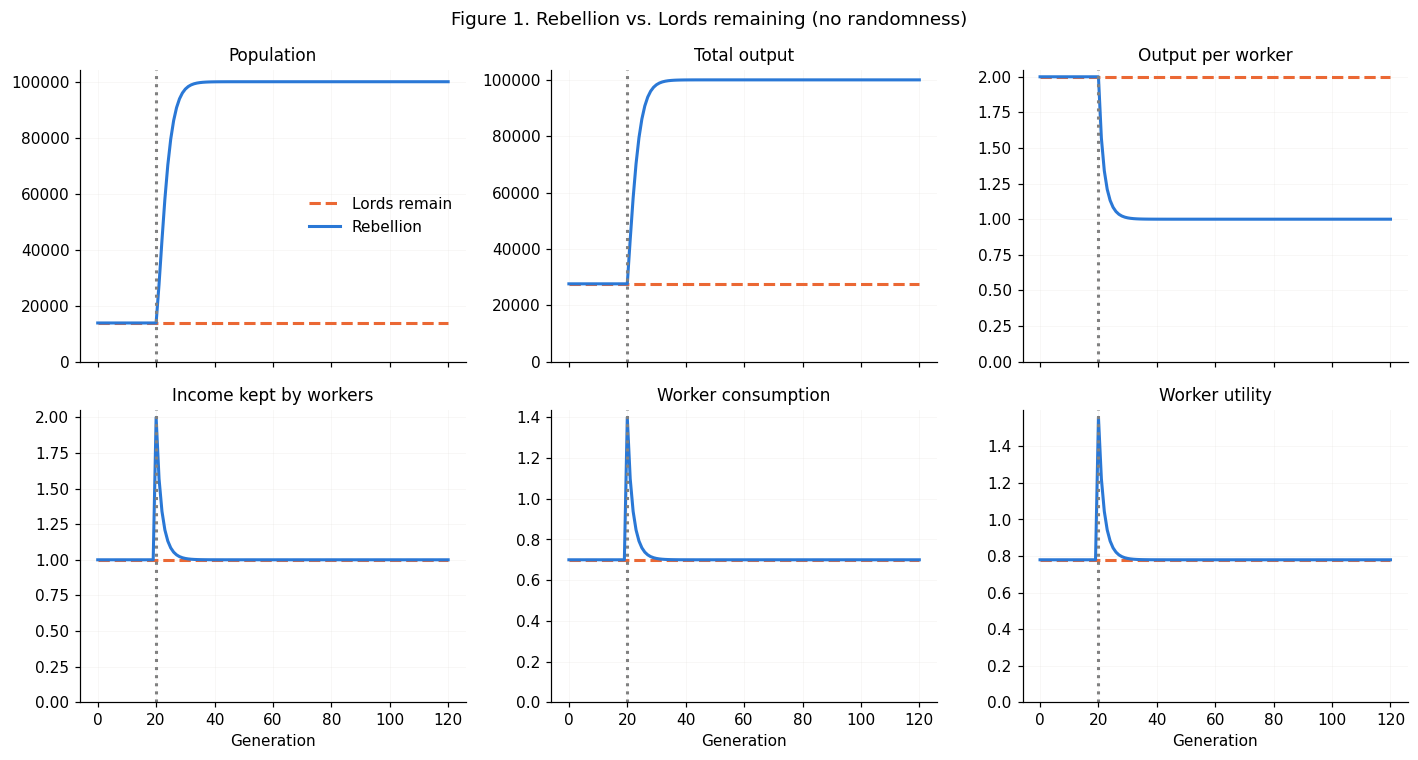

In [20]:
panels = {"population": "Population", "output": "Total output", "output_per_worker": "Output per worker", "income": "Income kept by workers", "consumption": "Worker consumption", "utility": "Worker utility"}

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, (column, title) in zip(axes.flat, panels.items()):
    ax.plot(lords[column], color=ORANGE, linestyle="--", label="Lords remain")
    ax.plot(rebel[column], color=BLUE, label="Rebellion")
    ax.axvline(REBELLION, color="gray", linestyle=":")
    ax.set_title(title)
    ax.set_ylim(bottom=0)
axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel("Generation")
fig.suptitle("Figure 1. Rebellion vs. Lords remaining (no randomness)")
fig.tight_layout()
fig.savefig(APPENDIX / "Figure1.png", dpi=300, bbox_inches="tight")
plt.show()

The top row changes for good: more people, more total output, less output per worker. The bottom row jumps at the rebellion and then returns to exactly where it was. The gains from the rebellion end up as more people, not as richer workers.

Quick checks that the simulation agrees with the equations from Section 2:

In [21]:
assert np.isclose(rebel.loc[20, "output"], lords.loc[20, "output"])
assert np.isclose(rebel.loc[20, "consumption"], 2 * lords.loc[20, "consumption"])
assert np.isclose(rebel.loc[20, "utility"], 2 * lords.loc[20, "utility"])
assert np.isclose(rebel["population"].iloc[-1], without_lords["population"])
assert np.isclose(rebel["consumption"].iloc[-1], lords["consumption"].iloc[-1])

gain = rebel["consumption"] / lords["consumption"] - 1
for h in [0, 1, 2, 5, 10]:
    print(f"{h:>2} generations after the rebellion, consumption is {gain[REBELLION + h]:.1%} higher")

 0 generations after the rebellion, consumption is 100.0% higher
 1 generations after the rebellion, consumption is 56.9% higher
 2 generations after the rebellion, consumption is 34.0% higher
 5 generations after the rebellion, consumption is 8.4% higher
10 generations after the rebellion, consumption is 0.9% higher


The gain halves (in log terms) about every 1.6 generations. Only $\alpha$ sets this speed: the gap shrinks by a factor of $\alpha$ each generation. A lower $\alpha$ means stronger diminishing returns, so population catches up faster.

## 4. Adding randomness

Real agricultural societies faced good and bad harvests and unpredictable births and deaths. We add both:

**Harvests.** Each generation, productivity is multiplied by a random shock $e^{\varepsilon - \sigma^2/2}$ with $\varepsilon \sim N(0, \sigma^2)$. The $-\sigma^2/2$ term keeps the average shock equal to 1. We use $\sigma = 0.1$, so a typical generation is about 10% better or worse than average. One shock stands for average conditions over a whole generation.

**Births.** Instead of exactly $n \times L$ workers in the next generation, the number is drawn from a Poisson distribution with that average. On average the population follows the same rule as before, but now it varies by chance.

Both scenarios get the **same harvest shocks**, so each comparison is between the same "world" with and without the Lords. Utility is still based on the number of children parents *expect*, because that is what they plan around.

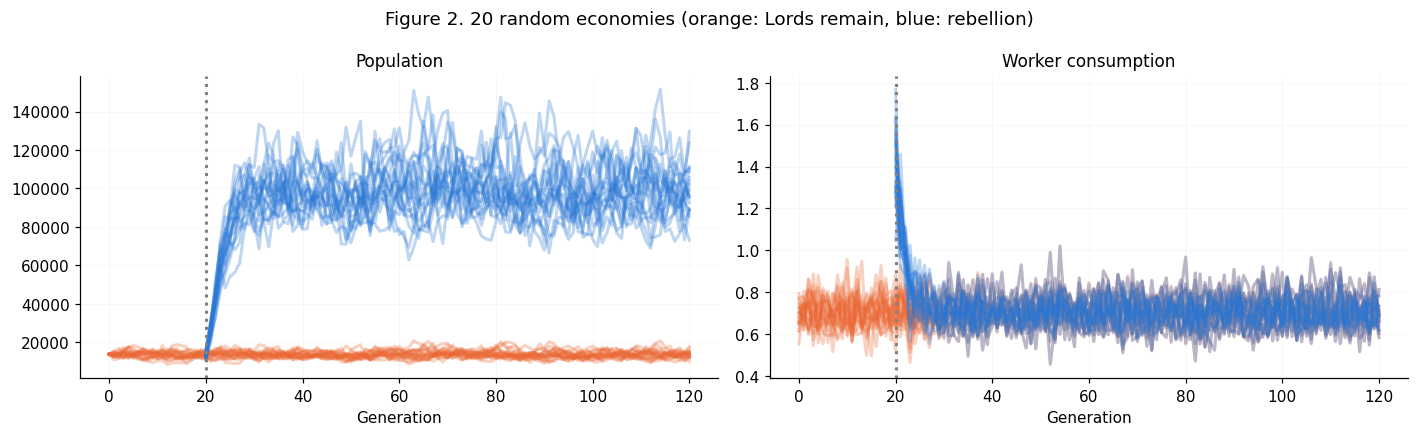

In [22]:
def simulate_random(taxes, L0, runs, p=params, sigma=0.1, seed=0):
    harvest_rng = np.random.default_rng(seed)
    birth_rng = np.random.default_rng(seed + 1)
    L = np.full(runs, round(L0), dtype=float)
    results = {key: np.zeros((runs, len(taxes))) for key in ["population", "output_per_worker", "consumption", "utility"]}
    for t, tax in enumerate(taxes):
        shock = np.exp(sigma * harvest_rng.standard_normal(runs) - sigma**2 / 2)
        result = generation(L, tax, p, shock)
        for key in results:
            results[key][:, t] = result[key]
        L = birth_rng.poisson(result["children"] * L).astype(float)
    return results


examples_rebel = simulate_random(tax_path(True), L0, runs=20)
examples_lords = simulate_random(tax_path(False), L0, runs=20)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column, title in [(axes[0], "population", "Population"), (axes[1], "consumption", "Worker consumption")]:
    ax.plot(examples_lords[column].T, color=ORANGE, alpha=0.3)
    ax.plot(range(REBELLION, GENERATIONS), examples_rebel[column][:, REBELLION:].T, color=BLUE, alpha=0.3)
    ax.axvline(REBELLION, color="gray", linestyle=":")
    ax.set_title(title)
    ax.set_xlabel("Generation")
fig.suptitle("20 random economies (orange: Lords remain, blue: rebellion)")
fig.tight_layout()
plt.show()

Even with the noise, the pattern from Figure 1 is clear: consumption jumps at the rebellion and fades, and population climbs to a new, higher level.

## 5. Monte Carlo: 5,000 economies

We now run 5,000 random economies under each scenario. For each run, we measure the effect of the rebellion as the difference between the two scenarios in that same world (same harvests). The average across runs tells us the expected effect. The spread across runs tells us how much the effect depends on luck.

In [23]:
RUNS = 5000

mc_rebel = simulate_random(tax_path(True), L0, RUNS)
mc_lords = simulate_random(tax_path(False), L0, RUNS)

assert (mc_rebel["population"] > 0).all() and (mc_lords["population"] > 0).all()

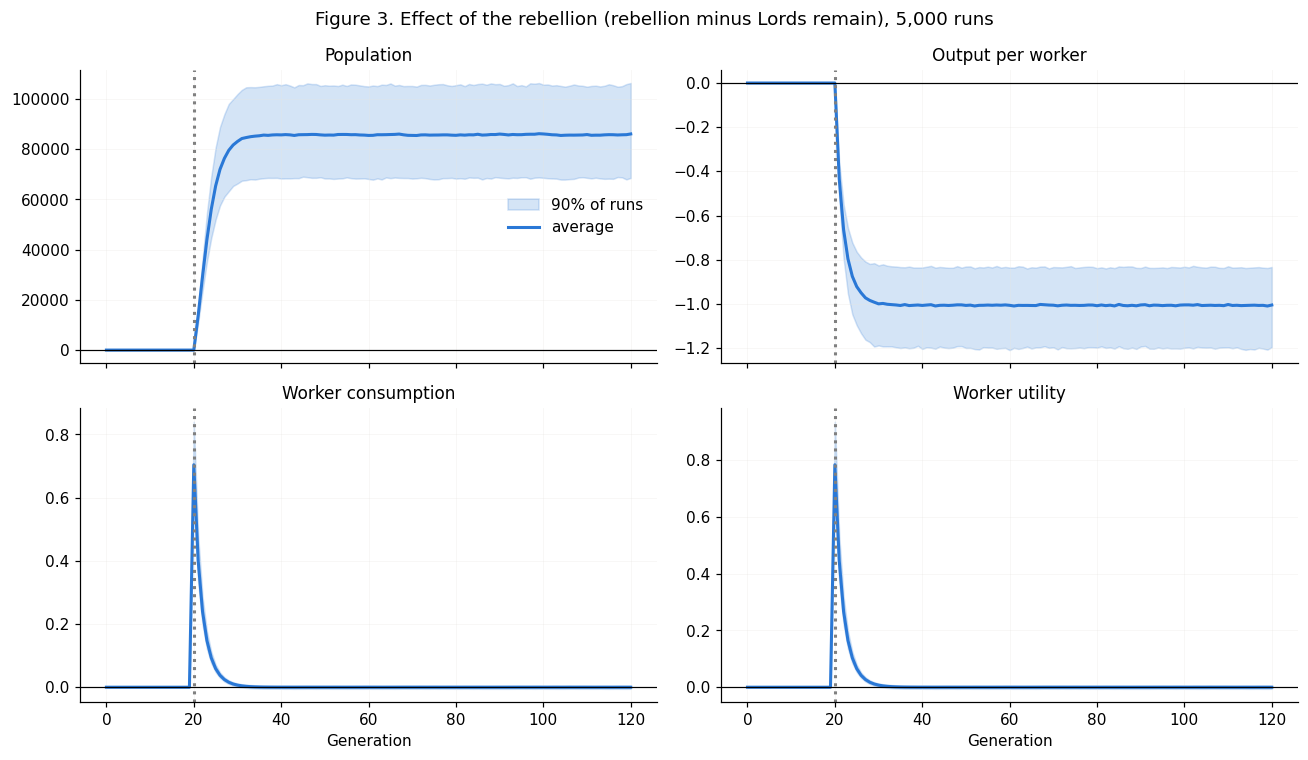

In [24]:
titles = {"population": "Population", "output_per_worker": "Output per worker", "consumption": "Worker consumption", "utility": "Worker utility"}

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (column, title) in zip(axes.flat, titles.items()):
    difference = mc_rebel[column] - mc_lords[column]
    ax.fill_between(range(GENERATIONS), np.percentile(difference, 5, axis=0), np.percentile(difference, 95, axis=0),
                    color=BLUE, alpha=0.2, label="90% of runs")
    ax.plot(difference.mean(axis=0), color=BLUE, label="average")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(REBELLION, color="gray", linestyle=":")
    ax.set_title(title)
axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel("Generation")
fig.suptitle("Figure 2. Effect of the rebellion (rebellion minus Lords remain), 5,000 runs")
fig.tight_layout()
fig.savefig(APPENDIX / "Figure2.png", dpi=300, bbox_inches="tight")
plt.show()

The averages look just like the no-randomness model. The shaded band shows the range across 90% of runs. Harvest luck changes the *size* of the effects, but never their direction.

**How long do the workers' gains last?** The table shows the consumption gain at different horizons. "95% CI" is the uncertainty in our estimate of the average, which is small because we ran 5,000 economies.

In [25]:
consumption_gain = mc_rebel["consumption"] / mc_lords["consumption"] - 1

rows = []
for h in [0, 1, 5, 10, 25, 50, 100]:
    g = consumption_gain[:, REBELLION + h]
    margin = 1.96 * g.std() / np.sqrt(RUNS)
    rows.append({"generations after rebellion": h,
                 "average gain": f"{g.mean():.2%}",
                 "95% CI": f"{g.mean() - margin:.2%} to {g.mean() + margin:.2%}",
                 "share of runs better off": (g > 0).mean(),
                 "share of runs >1% better off": (g > 0.01).mean()})
pd.DataFrame(rows).set_index("generations after rebellion")

,average gain,95% CI,share of runs better off,share of runs >1% better off
generations after rebellion,,,,
0,100.00%,100.00% to 100.00%,1,1
1,56.91%,56.90% to 56.93%,1,1
5,8.37%,8.36% to 8.38%,1,1
10,0.94%,0.93% to 0.95%,0.9856,0.4496
25,0.01%,-0.00% to 0.02%,0.5172,0.0094
50,0.00%,-0.01% to 0.01%,0.4992,0.007
100,-0.01%,-0.02% to 0.01%,0.4952,0.0064


For the first five generations, workers are better off in every single run, and at ten generations they still are in about 99% of runs. After that, the gain becomes too small to matter: by generation 25, fewer than 1% of runs are more than 1% better off. The "share better off" column then settles near 50%. At that point the two scenarios differ only by random birth noise, so which one is slightly ahead is a coin flip.

In [26]:
def generations_until_gain_fades(rebel, lords):
    gain = (rebel["consumption"] / lords["consumption"] - 1).mean(axis=0)
    return int(np.argmax(gain[REBELLION:] < 0.01))


print("Generations until the average gain is below 1%")
print("  without randomness:", int(np.argmax(gain[REBELLION:].values < 0.01)))
print("  with randomness:   ", generations_until_gain_fades(mc_rebel, mc_lords))

Generations until the average gain is below 1%
  without randomness: 10
  with randomness:    10


Randomness does not change how long the gains last. Since both scenarios face the same harvests, a good or bad harvest raises or lowers consumption in both by the same proportion, so the gap between them closes at the same speed as before.

## 6. How sensitive are the results?

We rerun the Monte Carlo (1,000 runs each) while changing one thing at a time: the size of the harvest shocks, the labor share $\alpha$, the value parents place on children $\gamma$, and how much the Lords took to begin with.

In [27]:
def run_experiment(p=params, sigma=0.1, tax=TAX_LORDS, runs=1000):
    taxes_lords = np.full(GENERATIONS, tax)
    taxes_rebel = taxes_lords.copy()
    taxes_rebel[REBELLION:] = 0
    start = equilibrium_population(tax, p)
    rebel = simulate_random(taxes_rebel, start, runs, p, sigma)
    lords = simulate_random(taxes_lords, start, runs, p, sigma)
    return {"population ratio (long run)": rebel["population"][:, -1].mean() / lords["population"][:, -1].mean(), "consumption gain after 1 gen": (rebel["consumption"] / lords["consumption"] - 1)[:, REBELLION + 1].mean(), "generations until gain < 1%": generations_until_gain_fades(rebel, lords)}

experiments = {"baseline": {}}
for sigma in [0.0, 0.05, 0.2]:
    experiments[f"harvest shocks = {sigma}"] = {"sigma": sigma}
for alpha in [0.4, 0.5, 0.75]:
    experiments[f"alpha = {alpha}"] = {"p": {**params, "alpha": alpha}}
for gamma in [0.2, 0.4]:
    experiments[f"gamma = {gamma}"] = {"p": {**params, "gamma": gamma}}
for tax in [0.25, 0.75]:
    experiments[f"Lords take {tax:.0%}"] = {"tax": tax}

pd.DataFrame({name: run_experiment(**settings) for name, settings in experiments.items()}).T.round(3)

,population ratio (long run),consumption gain after 1 gen,generations until gain < 1%
baseline,7.246,0.569,10
harvest shocks = 0.0,7.247,0.569,10
harvest shocks = 0.05,7.246,0.569,10
harvest shocks = 0.2,7.246,0.569,10
alpha = 0.4,3.175,0.32,5
alpha = 0.5,4,0.414,7
alpha = 0.75,16.007,0.682,15
gamma = 0.2,7.248,0.569,10
gamma = 0.4,7.247,0.569,10
Lords take 25%,2.275,0.206,8


The conclusion holds in every case: the consumption gain is temporary, and it is gone within 5 to 15 generations. The size of the shocks and how much parents value children ($\gamma$) barely matter. What matters is:

- **$\alpha$**, which sets how fast the gain fades. Stronger diminishing returns (low $\alpha$) make population catch up faster.
- **How much the Lords took**, which sets how large the long-run population boom is. If the Lords took 75%, the population ends up about 50 times larger.

## 7. Inequality and testable predictions

Because the Lords are a negligible share of the population, the share of output they take, $\tau$, works as the measure of inequality. (With a tiny elite holding a share $\tau$ of income, the Gini coefficient approaches $\tau$.) Comparing equilibria with different $\tau$, the model predicts that more extraction leads to:

- **fewer people**, since $\frac{d \ln L^*}{d\tau} = -\frac{1}{(1-\alpha)(1-\tau)}$,
- **less total output**,
- **higher output per worker**, since each worker has more land,
- **no change in workers' living standards.**

The third prediction is counterintuitive. A society with more inequality would look *richer* if you measured output per person, even though its workers are no better off.

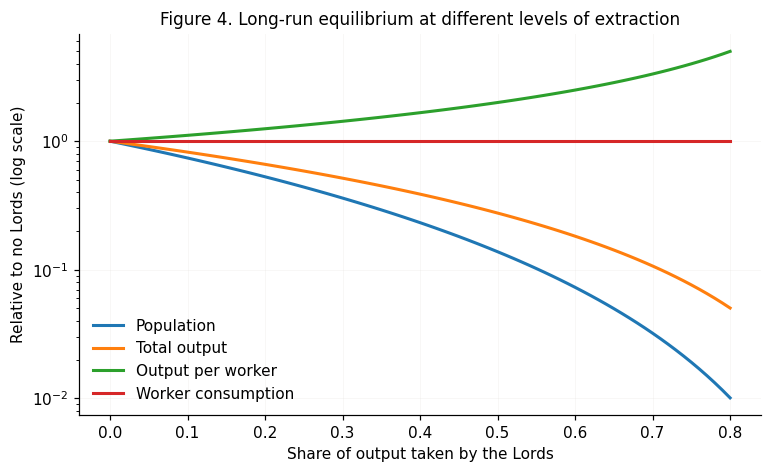

In [28]:
taxes = np.linspace(0, 0.8, 81)
equilibria = pd.DataFrame([generation(equilibrium_population(tax), tax) for tax in taxes], index=taxes)

fig, ax = plt.subplots(figsize=(8, 4.5))
for column, label in [("population", "Population"), ("output", "Total output"), ("output_per_worker", "Output per worker"), ("consumption", "Worker consumption")]:ax.plot(taxes, equilibria[column] / equilibria[column].iloc[0], label=label)
ax.set_yscale("log")
ax.set_xlabel("Share of output taken by the Lords")
ax.set_ylabel("Relative to no Lords (log scale)")
ax.set_title("Figure 3. Long-run equilibrium at different levels of extraction")
ax.legend()
fig.savefig(APPENDIX / "Figure3.png", dpi=300, bbox_inches="tight")
plt.show()

**How could this be tested?** One approach is to compare regions where elite extraction (feudal dues, rents, taxes) fell sharply with similar regions where it did not, using panel data over time. This is the difference-in-differences setup from lecture:

$$\text{outcome}_{it} = \beta_0 + \beta_1 \tau_{it} + \phi_i + \eta_t + \epsilon_{it}$$

The outcomes would be population density, baptisms from parish registers, real wages, and output per person. The model predicts that after extraction falls, real wages rise briefly and then return to their old level, while births and population rise and stay higher.

There are several problems to watch for:

- regions that ended extraction may already have been on different paths (parallel trends),
- revolts may happen *because* of population pressure (reverse causality),
- rebellions destroy people and crops, much like the Black Death,
- people may migrate toward places where they keep more of their output,
- technology or institutions may change at the same time,
- historical records of dues and wages are imperfect.

The model would be contradicted if real wages stayed higher for several generations after extraction fell without any rise in births or population.

## 8. Conclusion

With the Lords in place, workers live at the same level they would without them; the Lords' share is paid for with a smaller population. The rebellion doubles workers' consumption and utility immediately. But it also doubles the number of children each worker raises, and over the next generations population grows about 7 times, total output grows about 3.6 times, and output per worker halves. Workers' consumption returns exactly to where it started, with most of the gain gone within five generations.

Adding random harvests and random births does not change this. Across 5,000 simulated economies, workers are better off in every run for the first five generations and in about 99% of runs after ten, and then the gain disappears on the same schedule as in the model without randomness.

## References

- Ashraf, Q., and O. Galor (2011). "Dynamics and Stagnation in the Malthusian Epoch." *American Economic Review* 101(5): 2003–2041.
- Malthus, T. R. (1798). *An Essay on the Principle of Population.* London: J. Johnson.
- ECON 324 lecture slides, "The Malthusian Epoch."

## Exporting Figures and Tables for the Paper

Figures 1, 2 and 3 above are saved to `Appendix/` as `Figure1.png`, `Figure2.png` and `Figure3.png` when their cells run. The cell below saves the equilibrium table (Section 2) and the consumption gain table (Section 5) as `Table1.png` and `Table2.png`. Run the whole notebook from the top first.

In [ ]:
def save_table(df, path):
    fig, ax = plt.subplots(figsize=(8, 0.4 * (len(df) + 1)))
    ax.axis("off")
    cells = ax.table(cellText=df.values, rowLabels=df.index, colLabels=df.columns, loc="center")
    cells.auto_set_font_size(False)
    cells.set_fontsize(11)
    cells.scale(1, 1.5)
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.close(fig)


fmt = lambda v: f"{v:,.3f}".rstrip("0").rstrip(".")
save_table(table.drop(index="children").map(fmt), APPENDIX / "Table1.png")

consumption_table = pd.DataFrame(rows).set_index("generations after rebellion")
save_table(consumption_table.loc[[0, 5, 10, 25, 50], ["average gain", "95% CI", "share of runs better off"]], APPENDIX / "Table2.png")